In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm
import pandas as pd

import matplotlib.font_manager as fm

chinese_fonts = [f.name for f in fm.fontManager.ttflist if 'Chinese' in f.name or 'Song' in f.name or 'Hei' in f.name or 'Kai' in f.name or 'Fang' in f.name]

if chinese_fonts:
    print("可用的中文字体:", chinese_fonts[:5]) 
    plt.rcParams['font.sans-serif'] = [chinese_fonts[0], 'SimHei', 'Microsoft YaHei']
else:
    print("未找到中文字体，将使用英文显示")
    
plt.rcParams['axes.unicode_minus'] = False

可用的中文字体: ['STFangsong', 'Microsoft YaHei', 'Microsoft JhengHei', 'Microsoft JhengHei', 'Microsoft JhengHei']


In [12]:
# 定义 Beale 函数
def beale(x1, x2):
    term1 = (1.5 - x1 + x1 * x2) ** 2
    term2 = (2.25 - x1 + x1 * x2**2) ** 2
    term3 = (2.625 - x1 + x1 * x2**3) ** 2
    return term1 + term2 + term3

# 定义 Beale 函数的梯度
def gradient_beale(x1, x2):
    a = 1.5 - x1 + x1 * x2
    b = 2.25 - x1 + x1 * x2**2
    c = 2.625 - x1 + x1 * x2**3
    df_dx1 = 2 * a * (-1 + x2) + 2 * b * (-1 + x2**2) + 2 * c * (-1 + x2**3)
    df_dx2 = 2 * a * x1 + 2 * b * (2 * x1 * x2) + 2 * c * (3 * x1 * x2**2)
    return df_dx1, df_dx2

In [23]:
# 梯度下降参数设置
x1 = 1.0  # 初始值
x2 = 1.0  # 初始值
lr = 0.01  # 学习率
iterations = 2000  # 迭代次数

# 存储迭代历史
history = []

# 梯度下降迭代
for i in range(iterations):
    grad_x1, grad_x2 = gradient_beale(x1, x2)
    x1_new = x1 - lr * grad_x1
    x2_new = x2 - lr * grad_x2
    f_value = beale(x1, x2)
    history.append((x1, x2, f_value, grad_x1, grad_x2))
    x1, x2 = x1_new, x2_new

# 转换为DataFrame以便分析
df_history = pd.DataFrame(history, columns=['x1', 'x2', 'f_value', 'grad_x1', 'grad_x2'])
df_history['iteration'] = range(1, len(history)+1)

# 输出最终结果
print("梯度下降优化结果:")
print(f"最终点: (x1, x2) = ({history[-1][0]:.6f}, {history[-1][1]:.6f})")
print(f"最终函数值: {history[-1][2]:.6f}")
print(f"全局最小值点: (3, 0.5), 函数值: 0")

# 显示迭代历史
print("\n迭代历史:")
display(df_history)

梯度下降优化结果:
最终点: (x1, x2) = (2.999153, 0.499789)
最终函数值: 0.000000
全局最小值点: (3, 0.5), 函数值: 0

迭代历史:


,x1,x2,f_value,grad_x1,grad_x2,iteration
0,1.000000,1.000000,1.420312e+01,0.000000,27.750000,1
1,1.000000,0.722500,8.643115e+00,-4.866583,13.836905,2
2,1.048666,0.584131,6.750265e+00,-5.798198,9.884541,3
3,1.106648,0.485286,5.542215e+00,-6.018129,7.647213,4
4,1.166829,0.408813,4.655266e+00,-5.952700,6.128977,5
...,...,...,...,...,...,...
1995,2.999143,0.499786,1.177429e-07,-0.000259,-0.000065,1996
1996,2.999145,0.499787,1.170327e-07,-0.000258,-0.000064,1997
1997,2.999148,0.499787,1.163269e-07,-0.000257,-0.000064,1998
1998,2.999151,0.499788,1.156253e-07,-0.000256,-0.000064,1999


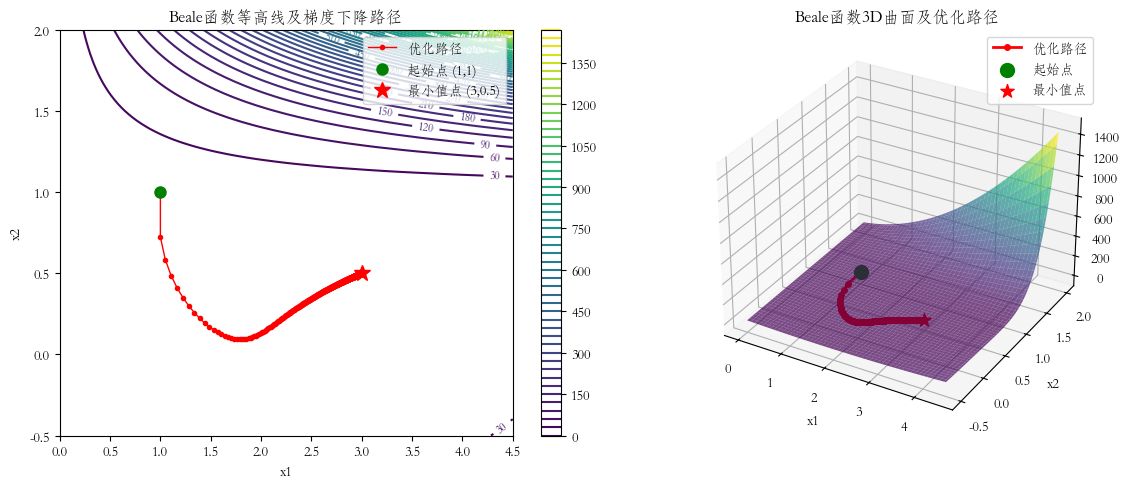

In [26]:
x1_range = np.linspace(0, 4.5, 100)
x2_range = np.linspace(-0.5, 2, 100)
X1, X2 = np.meshgrid(x1_range, x2_range)
Z = beale(X1, X2)

plt.figure(figsize=(12, 5))

# 等高线图
plt.subplot(1, 2, 1)
contour = plt.contour(X1, X2, Z, levels=50, cmap='viridis')
plt.clabel(contour, inline=True, fontsize=8)
plt.plot(df_history['x1'], df_history['x2'], 'ro-', markersize=3, linewidth=1, label='优化路径')
plt.plot(1.0, 1.0, 'go', markersize=8, label='起始点 (1,1)')
plt.plot(3.0, 0.5, 'r*', markersize=12, label='最小值点 (3,0.5)')
plt.xlabel('x1')
plt.ylabel('x2')
plt.title('Beale函数等高线及梯度下降路径')
plt.legend()
plt.colorbar(contour)

# 3D曲面图
ax = plt.subplot(1, 2, 2, projection='3d')
surf = ax.plot_surface(X1, X2, Z, cmap=cm.viridis, alpha=0.7)
ax.plot(df_history['x1'], df_history['x2'], df_history['f_value'], 'ro-', linewidth=2, markersize=4, label='优化路径')
ax.scatter([1.0], [1.0], [beale(1,1)], color='green', s=100, label='起始点')
ax.scatter([3.0], [0.5], [0], color='red', s=100, marker='*', label='最小值点')
ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_title('Beale函数3D曲面及优化路径')
ax.legend()

plt.tight_layout()
plt.show()

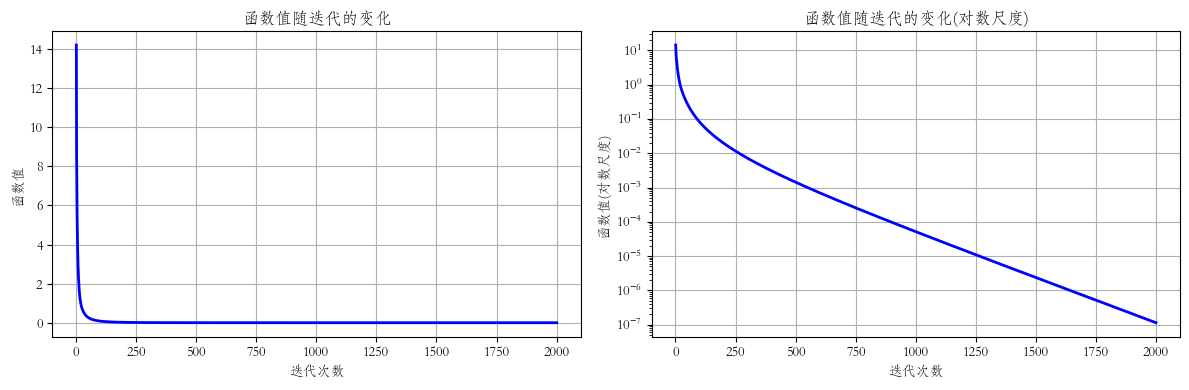

In [25]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(df_history['iteration'], df_history['f_value'], 'b-', linewidth=2)
plt.xlabel('迭代次数')
plt.ylabel('函数值')
plt.title('函数值随迭代的变化')
plt.grid(True)

plt.subplot(1, 2, 2)
plt.semilogy(df_history['iteration'], df_history['f_value'], 'b-', linewidth=2)
plt.xlabel('迭代次数')
plt.ylabel('函数值(对数尺度)')
plt.title('函数值随迭代的变化(对数尺度)')
plt.grid(True)

plt.tight_layout()
plt.show()

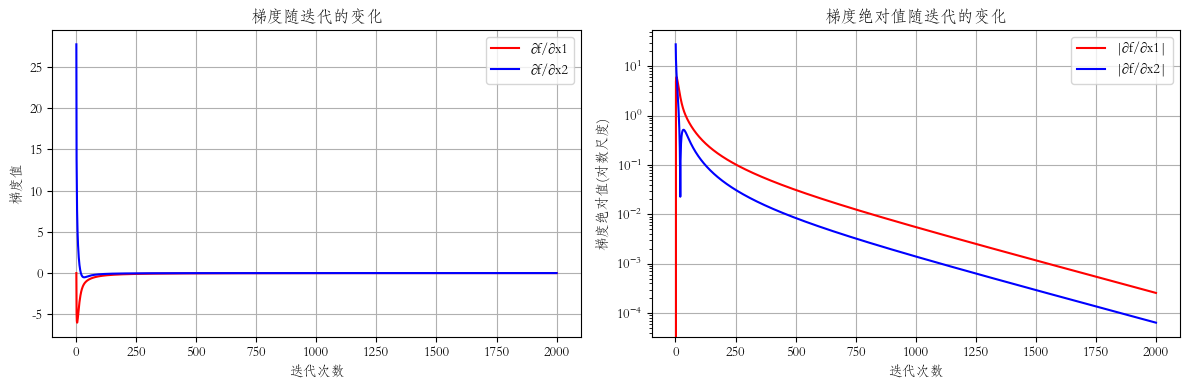

In [27]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(df_history['iteration'], df_history['grad_x1'], 'r-', label='∂f/∂x1')
plt.plot(df_history['iteration'], df_history['grad_x2'], 'b-', label='∂f/∂x2')
plt.xlabel('迭代次数')
plt.ylabel('梯度值')
plt.title('梯度随迭代的变化')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.semilogy(df_history['iteration'], np.abs(df_history['grad_x1']), 'r-', label='|∂f/∂x1|')
plt.semilogy(df_history['iteration'], np.abs(df_history['grad_x2']), 'b-', label='|∂f/∂x2|')
plt.xlabel('迭代次数')
plt.ylabel('梯度绝对值(对数尺度)')
plt.title('梯度绝对值随迭代的变化')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

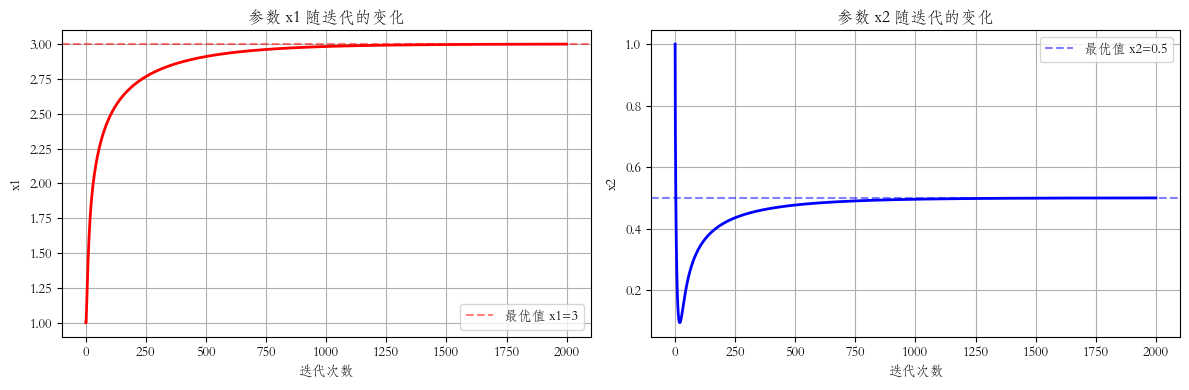

In [28]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(df_history['iteration'], df_history['x1'], 'r-', linewidth=2)
plt.axhline(y=3.0, color='r', linestyle='--', alpha=0.5, label='最优值 x1=3')
plt.xlabel('迭代次数')
plt.ylabel('x1')
plt.title('参数 x1 随迭代的变化')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(df_history['iteration'], df_history['x2'], 'b-', linewidth=2)
plt.axhline(y=0.5, color='b', linestyle='--', alpha=0.5, label='最优值 x2=0.5')
plt.xlabel('迭代次数')
plt.ylabel('x2')
plt.title('参数 x2 随迭代的变化')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [29]:
# 分析收敛情况
print("收敛分析:")
initial_value = beale(1.0, 1.0)
final_value = history[-1][2]
convergence_ratio = final_value / initial_value

print(f"初始函数值: {initial_value:.6f}")
print(f"最终函数值: {final_value:.6f}")
print(f"收敛比例: {convergence_ratio:.6f}")

# 计算最后几次迭代的变化率
last_changes = []
for i in range(1, 6):
    change = abs(history[-i][2] - history[-i-1][2]) / abs(history[-i-1][2]) if history[-i-1][2] != 0 else 0
    last_changes.append(change)

print(f"最后5次迭代的相对变化率: {last_changes}")
print(f"平均变化率: {np.mean(last_changes):.6f}")

# 检查是否接近全局最小值
distance_to_opt = np.sqrt((history[-1][0]-3.0)**2 + (history[-1][1]-0.5)**2)
print(f"与全局最小值的欧氏距离: {distance_to_opt:.6f}")

收敛分析:
初始函数值: 14.203125
最终函数值: 0.000000
收敛比例: 0.000000
最后5次迭代的相对变化率: [0.006031023124979652, 0.0060310559738632336, 0.006031088921773853, 0.006031121970575178, 0.006031155119304392]
平均变化率: 0.006031
与全局最小值的欧氏距离: 0.000873


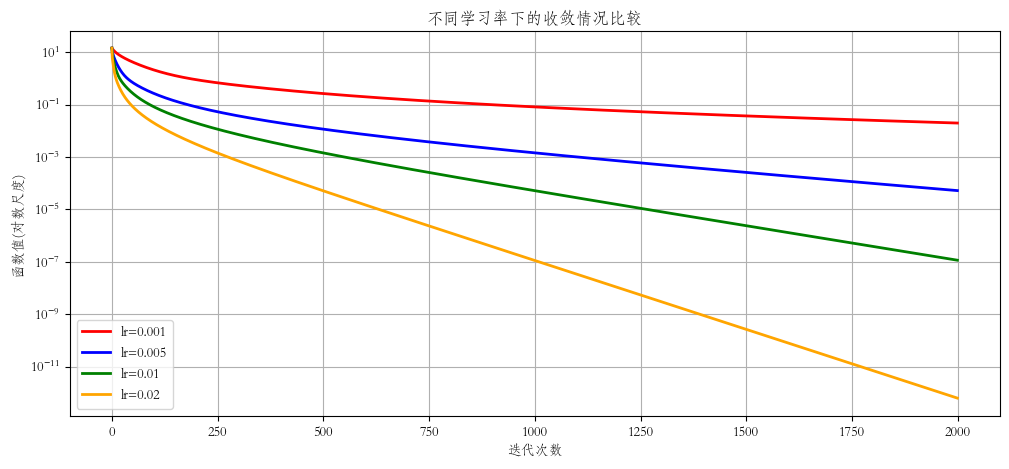

In [31]:
# 尝试不同的学习率比较
learning_rates = [0.001, 0.005, 0.01, 0.02]
colors = ['red', 'blue', 'green', 'orange']

plt.figure(figsize=(12, 5))

for i, lr in enumerate(learning_rates):
    # 重新运行梯度下降
    x1, x2 = 1.0, 1.0
    lr_history = []
    
    for it in range(iterations):
        grad_x1, grad_x2 = gradient_beale(x1, x2)
        x1_new = x1 - lr * grad_x1
        x2_new = x2 - lr * grad_x2
        f_value = beale(x1, x2)
        lr_history.append(f_value)
        x1, x2 = x1_new, x2_new
    
    plt.semilogy(range(iterations), lr_history, color=colors[i], linewidth=2, label=f'lr={lr}')

plt.xlabel('迭代次数')
plt.ylabel('函数值(对数尺度)')
plt.title('不同学习率下的收敛情况比较')
plt.legend()
plt.grid(True)
plt.show()